---
title: "ERCOT Analysis"
format:
  html:
    echo: false
---

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
ercot = pd.read_csv("../data/ercot_artifex.csv").query("type == 'LZ'")

ercot["time_utc"] = pd.to_datetime(ercot["datetime_utc"], format = "%m/%d/%y %H:%M")

ERCOT, the Electric Reliability Council of Texas, operates the power grid for most of Texas and runs its wholesale electricity market. The grid is divided into four load zones: Houston, North, South, and West. On December 5, 2025, ERCOT launched Real-Time Co-optimization plus Batteries (RTC+B), a redesign of its real-time market. Under RTC+B, energy and ancillary services are dispatched together every five minutes, and batteries are modeled as single units. ERCOT's goal was to give the grid more flexibility in real time and to procure energy and ancillary services more efficiently. This analysis examines how price spreads between the four load zones differ before and after RTC+B went live. Because the post-RTC+B period is short and covers different seasonal conditions, these comparisons show associations, not proof that RTC+B caused the changes.


The first graph shows the number of extreme price spreads by month. An extreme price spread is defined as a price spread between load zones that is in the 95th percentile of Pre-RTC+B price spreads. The graph shows that Post-RTC+B tends to have less extreme price spreads.

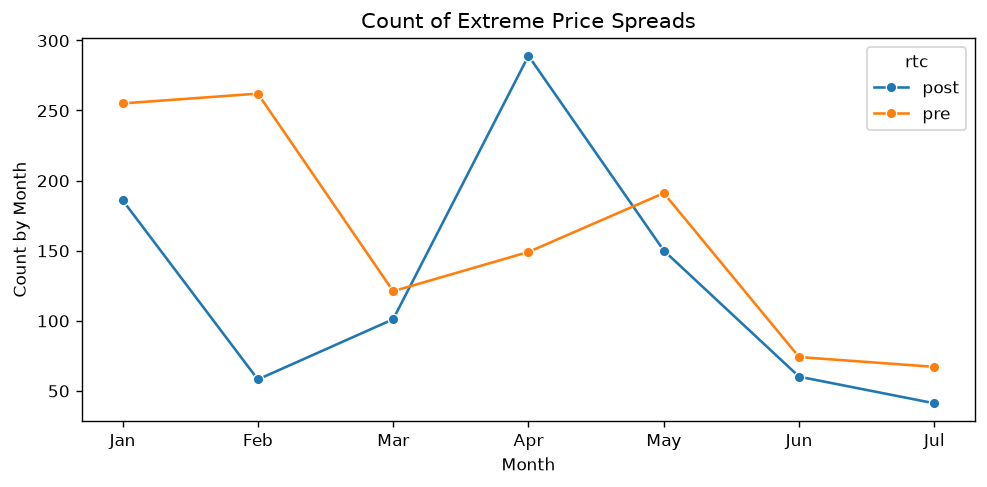

In [ ]:
ercot_extreme = (
    ercot.groupby("time_utc", as_index = False)
    .agg(spread = ("price", lambda x: x.max() - x.min()))
    .assign(rtc = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "Pre-RTCB", "Post-RTCB"),
    ext_spread = lambda x: np.where(x['spread'] >= x.loc[x["rtc"] == "pre","spread"].quantile(.95), "extreme", "normal"),
    month = lambda x: x["time_utc"].dt.month)
    .query("((time_utc > '2025-01-01') & (time_utc < '2025-07-25')) | ((time_utc > '2026-01-01') & (time_utc < '2026-07-25'))")
    .groupby(["month", "rtc"], as_index=False)
    .agg(count_by_month =("ext_spread", lambda x: (x == "extreme").sum()))
)

fig, ax = plt.subplots(figsize=(8, 4))

sns.lineplot(
    data=ercot_extreme,
    x="month",
    y="count_by_month",
    hue="rtc",
    marker = "o",
    ax=ax
)

ax.set_title("Count of Extreme Price Spreads")
ax.set_ylabel("Count by Month")
ax.set_xlabel("Month")
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul"])

plt.tight_layout()
plt.show()



This next graph shows the median price spread by the hour of the day. The median spread Pre-RTC+B is higher than Post-RTC+B before 12:00 but lower after. This could show the RTC+B's effect on efficiently storing energy throughout the day.

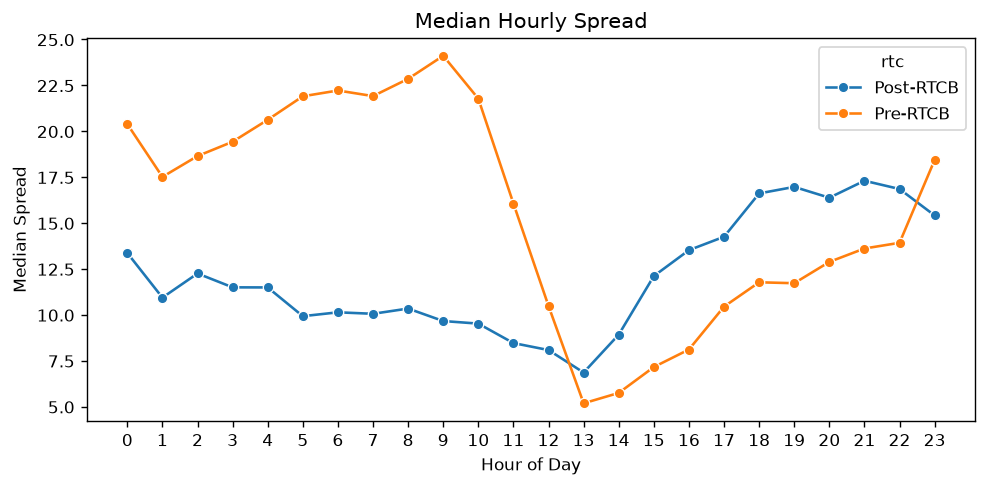

In [30]:
ercot_hourly_spread = (
    ercot.groupby("time_utc", as_index=False)
    .agg(spread = ("price", lambda x: x.max() - x.min()))
    .assign(rtc = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "Pre-RTCB", "Post-RTCB"),
    hour_utc = lambda x: x["time_utc"].dt.hour)
    .query("((time_utc > '2025-01-01') & (time_utc < '2025-07-25')) | ((time_utc > '2026-01-01') & (time_utc < '2026-07-25'))")
    .groupby(["hour_utc", "rtc"])
    .agg(hourly_median = ("spread", lambda x: x.median()))
)

fig, ax1 = plt.subplots(figsize=(8, 4))

sns.lineplot(
    data = ercot_hourly_spread,
    x = "hour_utc",
    y = "hourly_median",
    hue = "rtc",
    marker = "o",
    ax=ax1
)

ax1.set_title("Median Hourly Spread")
ax1.set_ylabel("Median Spread")
ax1.set_xlabel("Hour of Day")
ax1.set_xticks(range(24))
ax1.set_xticklabels(range(24))

plt.tight_layout()
plt.show()




These next three graphs show the Western load zone's median price difference compared to the other three load zones in ERCOT. One trend that emerges from the plots is that Post-RTC+B tends to have lower price difference between load zones with the exception of the Houston load zone, which is more volatile.

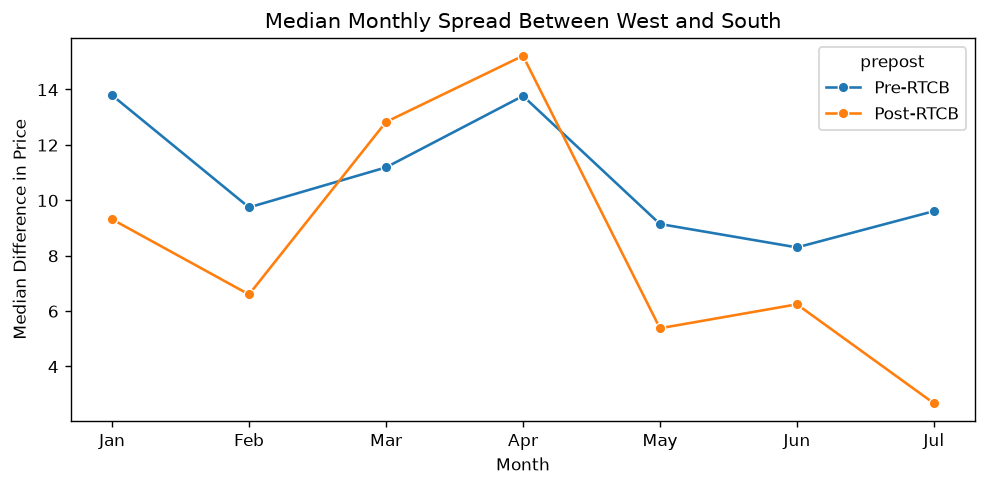

In [31]:
ercot_plot_south = (
    ercot.pivot(index = ["time_utc"], columns = "spn", values = "price").reset_index()
    .assign(wdiff = lambda x: abs(x["LZ_WEST"] - x["LZ_SOUTH"]),
     month = lambda x: x["time_utc"].dt.month,
     prepost = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "Pre-RTCB", "Post-RTCB"))
    .query("month <= 7")
    .groupby(["month", "prepost"], as_index = False)
    .agg(ew = ("wdiff", lambda x: x.median()))

)

fig, ax2 = plt.subplots(figsize=(8, 4))

sns.lineplot(
        data = ercot_plot_south,
        x = "month",
        y = "ew",
        hue = "prepost",
        hue_order=  ["Pre-RTCB", "Post-RTCB"],
        marker = "o",
        ax = ax2
    )

ax2.set_title("Median Monthly Spread Between West and South")
ax2.set_ylabel("Median Difference in Price")
ax2.set_xlabel("Month")
ax2.set_xticks([1, 2, 3, 4, 5, 6, 7], ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul'])

plt.tight_layout()
plt.show()



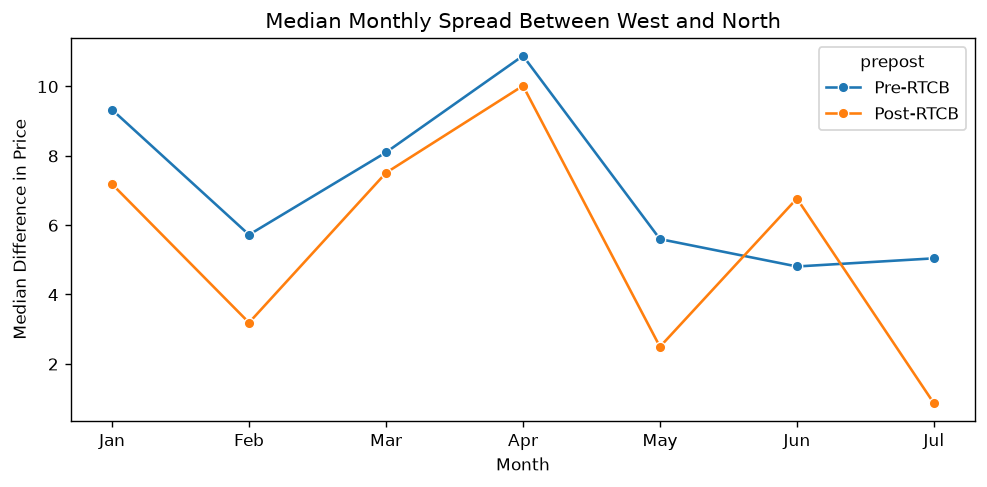

In [32]:
ercot_plot_north = (
    ercot.pivot(index = ["time_utc"], columns = "spn", values = "price").reset_index()
    .assign(wdiff = lambda x: abs(x["LZ_WEST"] - x["LZ_NORTH"]),
     month = lambda x: x["time_utc"].dt.month,
     prepost = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "Pre-RTCB", "Post-RTCB"))
    .query("month <= 7")
    .groupby(["month", "prepost"], as_index = False)
    .agg(ew = ("wdiff", lambda x: x.median()))

)

fig, ax3 = plt.subplots(figsize=(8, 4))

sns.lineplot(
        data = ercot_plot_north,
        x = "month",
        y = "ew",
        hue = "prepost",
        hue_order=  ["Pre-RTCB", "Post-RTCB"],
        marker = "o",
        ax = ax3
    )

ax3.set_title("Median Monthly Spread Between West and North")
ax3.set_ylabel("Median Difference in Price")
ax3.set_xlabel("Month")
ax3.set_xticks([1, 2, 3, 4, 5, 6, 7], ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul'])

plt.tight_layout()
plt.show()


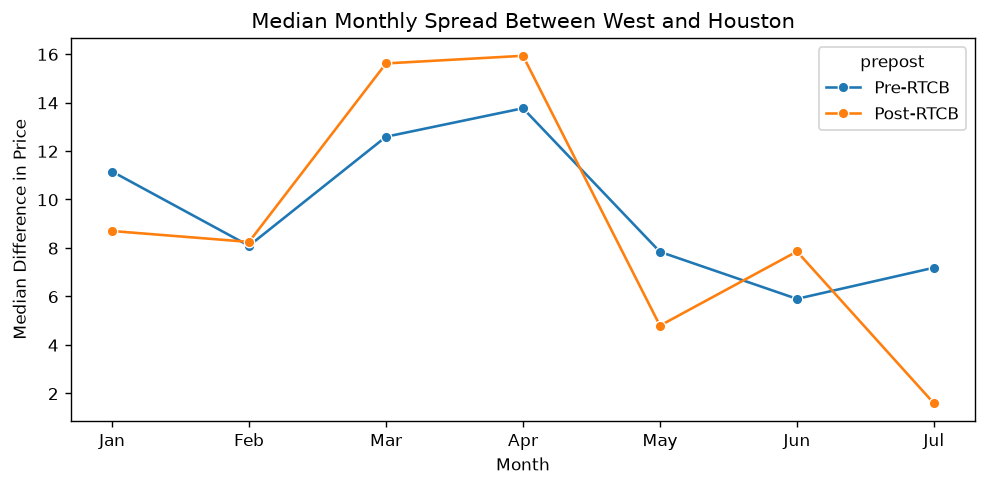

In [33]:
ercot_plot_houston = (
    ercot.pivot(index = ["time_utc"], columns = "spn", values = "price").reset_index()
    .assign(wdiff = lambda x: abs(x["LZ_WEST"] - x["LZ_HOUSTON"]),
     month = lambda x: x["time_utc"].dt.month,
     prepost = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "Pre-RTCB", "Post-RTCB"))
    .query("month <= 7")
    .groupby(["month", "prepost"], as_index = False)
    .agg(ew = ("wdiff", lambda x: x.median()))

)

fig, ax4 = plt.subplots(figsize=(8, 4))

sns.lineplot(
        data = ercot_plot_houston,
        x = "month",
        y = "ew",
        hue = "prepost",
        hue_order=  ["Pre-RTCB", "Post-RTCB"],
        marker = "o",
        ax = ax4
    )

ax4.set_title("Median Monthly Spread Between West and Houston")
ax4.set_ylabel("Median Difference in Price")
ax4.set_xlabel("Month")
ax4.set_xticks([1, 2, 3, 4, 5, 6, 7], ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul'])

plt.tight_layout()
plt.show()
